This notebook trains a handwriting synthesis model on the combined IAM-OnDB and DeepWriting data produced by `03-combine-data`.

It replaces the encoder-decoder model of `02-model` with the architecture from Graves, [*Generating Sequences With Recurrent Neural Networks*](https://arxiv.org/abs/1308.0850) (2013), updated with what has been learnt since:

- **Gaussian window attention** in place of dot-product attention. The window can only move forward through the text, so the model cannot skip or repeat letters. It is parameterised as in Battenberg et al., [*Location-Relative Attention Mechanisms for Robust Long-Form Speech Synthesis*](https://arxiv.org/abs/1910.10288) (2020), which is more robust than Graves' original.
- **Three LSTM layers with skip connections** rather than two attention layers.
- A **mixture density loss computed in log space**, which is numerically stable and has no clipping dead zones.
- **Adam at 1e-3** with learning rate decay and dropout, instead of 1e-4 and no regularisation.
- **Zero padding** instead of a sentinel value, with the mask derived from the pen state.

In [1]:
from datetime import datetime
import json
from pathlib import Path

import hashlib
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

In [2]:
# mount drive

from google.colab import drive

drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


# Load Data

Your project should be structured as follows:

```
.
├── data/
│   ├── raw/
│   │   ├── deepwriting/
│   │   └── iamondb/
│   └── cleaned/
├── checkpoints/
└── notebooks/
```

This notebook reads the most recent `combined-*` dataset from the `cleaned` directory and writes checkpoints to `checkpoints`. On Colab, point `ROOT` at a Google Drive folder so the checkpoints survive a disconnect.

In [3]:
# Change this to your project root

ROOT = Path("/content/drive/My Drive/handwriting-synthesis")

DATA_DIR = ROOT / "data" / "cleaned"
if not DATA_DIR.exists():
    raise FileNotFoundError("the 'cleaned' subdirectory does not exist")

CHECKPOINTS_DIR = ROOT / "checkpoints"
if not CHECKPOINTS_DIR.exists():
    raise FileNotFoundError("the 'checkpoints' directory does not exist")

In [4]:
# Specify where the weights and configs live

# ------------------------------ comment out one of these

run_dir = CHECKPOINTS_DIR / datetime.now().strftime("%Y-%m-%dT%H-%M-%S")
run_dir.mkdir()

# run_dir = CHECKPOINTS_DIR / "2026-11-12T14-45-00"

# ------------------------------

config_path = run_dir / "config.json"
config = json.loads(config_path.read_text()) if config_path.exists() else {}

if config:
    print("Using the config in", config_path)
else:
    print("No config yet: computing one from the data")

No config yet: computing one from the data


In [5]:
def load_data(path: Path) -> tuple[list[np.ndarray], list[str], list[str]]:
    with np.load(path / "strokes_data.npz") as data:
        strokes_data = [data[f"arr_{i}"] for i in range(len(data.files))]

    with open(path / "texts.json") as f:
        texts = json.load(f)

    # Whether each sample is "real" pen data or "synthetic" (traced by InkSight)
    sources_path = path / "sources.json"
    if sources_path.exists():
        with open(sources_path) as f:
            sources = json.load(f)
    else:
        sources = ["real"] * len(texts)

    return strokes_data, texts, sources

In [6]:
# The folder names end in a timestamp, so the latest one sorts last

data_path = max(DATA_DIR.glob("combined-*"))
strokes_data, texts, sources = load_data(data_path)

print(f"Loaded {len(strokes_data)} samples from {data_path.name}")

Loaded 17210 samples from combined-2026-11-12T10-04-33


In [7]:
# Every sample has a text, starts with the SOS token and ends with the EOS token

sos = np.array([0, 0, 1, 0, 0], dtype=np.float32)
eos = np.array([0, 0, 0, 0, 1], dtype=np.float32)

assert len(strokes_data) == len(texts) == len(sources)
assert all((strokes[0] == sos).all() and (strokes[-1] == eos).all() for strokes in strokes_data)

In [8]:
# Draws the pen strokes of a sample. Strokes are [dx, dy, pen_down, pen_up, eos] rows.

def draw_strokes(strokes: np.ndarray, label: str | None = None):
    coordinates = strokes[:, :2].cumsum(axis=0)
    pen_lifts = np.flatnonzero(strokes[:, 3])

    plt.figure(figsize=(12, 3))
    plt.plot(coordinates[:, 0], -coordinates[:, 1], "y:", alpha=0.4)

    for stroke in np.split(coordinates, pen_lifts + 1)[:-1]:
        plt.plot(stroke[:, 0], -stroke[:, 1], ".-", color="black")

    plt.title(label)
    plt.axis("off")
    plt.tight_layout()
    plt.show()

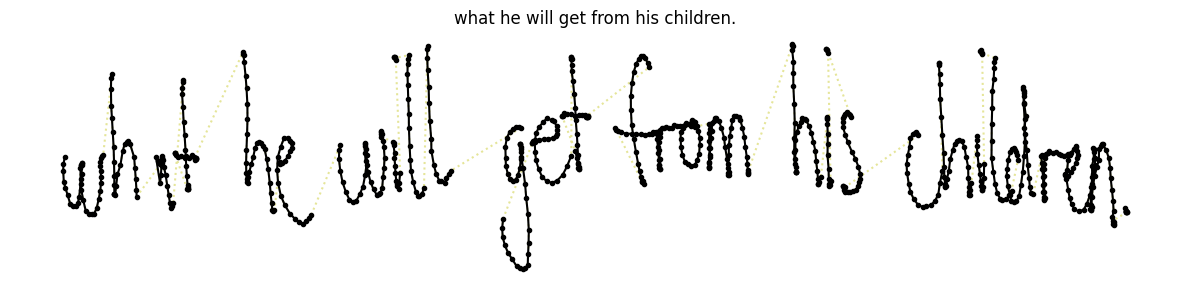

In [9]:
idx = 423

draw_strokes(strokes_data[idx], texts[idx])

# Preprocess Data

The model trains on sequences of pen offsets. To prepare the data we:

1. Split the data into training and validation sets.
2. Normalise the offsets.
3. Shift the strokes by one step to make inputs and targets, and pad them to equal length.
4. Vectorise the texts.

### Split

The data is split three ways:

- **Training** (about 90%) is what the model learns from.
- **Validation** (5%) picks the best checkpoint, lowers the learning rate and stops training. The model is tuned to it, so its loss flatters the model a little.
- **Test** (5%) is not used here at all. It is kept to compare trained models, once, at the end.

Each sample goes to a split by a hash of its text, not by shuffling, for two reasons:

1. **No line is seen twice.** IAM-OnDB and DeepWriting had writers copy the same lines, so many texts are written by several people. Shuffling put about half the validation lines' texts in the training set too, in another writer's hand. Hashing sends every writing of a text to the same split.
2. **Splits stay put.** Adding data never moves a sample to another split, so the test set means the same thing from one dataset to the next.

Synthetic samples always train. Scoring a model on InkSight's traces would measure how well it copies InkSight, and there are few enough of them to begin with.

In [10]:
seed = 42
tf.keras.utils.set_random_seed(seed)

VAL_FRACTION = 0.05
TEST_FRACTION = 0.05


def assign_split(text: str, source: str) -> str:
    """
    Assigns a sample to "train", "val" or "test" by a hash of its text.

    The hash is stable across runs and machines (unlike Python's `hash`), so the same text
    always lands in the same split.
    """
    if source == "synthetic":
        return "train"

    position = int.from_bytes(hashlib.sha256(text.encode()).digest()[:8]) / 2**64  # in [0, 1)
    if position < VAL_FRACTION:
        return "val"
    if position < VAL_FRACTION + TEST_FRACTION:
        return "test"
    return "train"


splits = np.array([assign_split(text, source) for text, source in zip(texts, sources)])


def select(split: str) -> tuple[list[np.ndarray], list[str]]:
    indices = np.flatnonzero(splits == split)
    return [strokes_data[i] for i in indices], [texts[i] for i in indices]


strokes_train, texts_train = select("train")
strokes_val, texts_val = select("val")
strokes_test, texts_test = select("test")

### Normalisation

The mean and standard deviation are computed on the training offsets only, excluding the EOS rows, whose offsets are synthetic. A single standard deviation for `dx` and `dy` keeps the handwriting's proportions.

In [11]:
if config:
    mean, std = np.array(config["mean"]), config["std"]
else:
    offsets = np.concatenate([strokes[:-1, :2] for strokes in strokes_train])
    mean, std = offsets.mean(axis=0), offsets.std()

print("Mean dx, dy:\t", mean)
print("Standard dev:\t", std)


def normalise(strokes: np.ndarray) -> np.ndarray:
    return np.column_stack([(strokes[:, :2] - mean) / std, strokes[:, 2:]])

Mean dx, dy:	 [0.08734933 0.0029931 ]
Standard dev:	 0.44123983


### Inputs and targets

At every step the model sees the strokes so far and predicts the next one, so the inputs are the strokes without the EOS token and the targets are the strokes without the SOS token. Sequences are padded with zeros: a padded row has no pen state set, which is how the loss recognises it.

In [12]:
def prepare(strokes_list: list[np.ndarray]) -> tuple[np.ndarray, np.ndarray]:
    normalised = [normalise(strokes) for strokes in strokes_list]
    inputs = tf.keras.utils.pad_sequences([s[:-1] for s in normalised], padding="post", dtype="float32")
    targets = tf.keras.utils.pad_sequences([s[1:] for s in normalised], padding="post", dtype="float32")
    return inputs, targets


inputs_train, targets_train = prepare(strokes_train)
inputs_val, targets_val = prepare(strokes_val)

assert (np.isfinite(inputs_train).all() and np.isfinite(targets_train).all())

print("Training set shape:\t", inputs_train.shape)
print("Validation set shape:\t", inputs_val.shape)

Training set shape:	 (15602, 1940, 5)
Validation set shape:	 (781, 1540, 5)


### Text vectorisation

In [13]:
# One position past the last character marks the end of the text (see the model below)
text_length = config.get("text_length", max(map(len, texts)) + 1)

text_vectorisation = tf.keras.layers.TextVectorization(
    standardize=None, split="character", output_sequence_length=text_length
)

if config:
    # The saved vocabulary starts with the padding and [UNK] tokens, which the layer adds itself
    text_vectorisation.set_vocabulary(config["vocabulary"][2:])
else:
    text_vectorisation.adapt(texts)

print("Vocabulary size:", text_vectorisation.vocabulary_size())
print("Longest text:", text_length)

Vocabulary size: 87
Longest text: 65


# Model

The text is embedded character by character; there is no encoder. The decoder has three LSTM layers:

- **Layer 1** is an LSTM paired with a *Gaussian window*. At every pen step the LSTM output sets the parameters of a mixture of Gaussians over character positions: a weight, a width and, crucially, a *step forward* for each one. The window position `kappa` is the running sum of those steps, so it can only move forward through the text. The window reads a blend of the character embeddings around `kappa`, which becomes `w`, the letter being written. Following Battenberg et al. (2020), the step and width go through `softplus` rather than `exp`, the weights through `softmax`, and the Gaussians are normalised, so `w` is a proper weighted average whatever the width. The step is biased to start at about one character per character's worth of pen steps, so an untrained window does not race off the end of the text. The window can also see one position past the last character: attention landing there means the text has ended, which is how `05-generate` knows when to stop writing.
- **Layers 2 and 3** are plain LSTMs. Every layer receives the strokes and `w`, and every layer's output feeds the output layer (Graves' skip connections), which is what makes a three-layer stack trainable. Because layer 1 produces the whole sequence of `w` under teacher forcing, these layers can be ordinary `LSTM` layers and use the fast cuDNN kernel.
- The **output layer** is linear. Its 123 numbers parameterise a mixture of 20 bivariate Gaussians over the next offset and the three pen state logits. The loss applies the activations itself and works in log space throughout.

In [14]:
units = config.get("units", 400)                          # LSTM units per layer
embed_dim = config.get("embed_dim", 64)                   # character embedding size
mixtures = config.get("mixtures", 20)                     # bivariate Gaussians in the output mixture
window_components = config.get("window_components", 10)  # Gaussians in the attention window
dropout = 0.1

# The window should start by advancing about one character per character's worth of pen steps
initial_step = config.get(
    "initial_step",
    1 / np.mean([len(strokes) / len(text) for strokes, text in zip(strokes_train, texts_train)]),
)

print(f"Initial window step: {initial_step:.3f} characters per pen step")

Initial window step: 0.049 characters per pen step


In [15]:
class GaussianWindow(tf.keras.layers.Layer):
    """
    Soft, monotonic attention over the text. Graves (2013), parameterised as
    GMMv2b from Battenberg et al. (2020).
    """

    def __init__(self, num_components: int, initial_step: float, **kwargs):
        super().__init__(**kwargs)
        self.step_offset = np.log(np.expm1(initial_step))  # softplus(step_offset) == initial_step
        self.params = tf.keras.layers.Dense(3 * num_components)

    def call(self, query, kappa, values, text_mask):
        logits, raw_sigma, raw_step = tf.split(self.params(query), 3, axis=-1)  # each (B, K)
        weight = tf.nn.softmax(logits)

        # Floor sigma - keeps the bump from vanishing between characters
        sigma = tf.nn.softplus(raw_sigma) + 0.1
        kappa = kappa + tf.nn.softplus(raw_step + self.step_offset)

        u = tf.range(tf.shape(values)[1], dtype=tf.float32)                   # (U,)
        z = (u - kappa[..., None]) / sigma[..., None]                          # (B, K, U)
        phi = tf.reduce_sum(weight[..., None] * tf.exp(-0.5 * tf.square(z)), axis=1) * text_mask
        phi = phi / (tf.reduce_sum(phi, axis=-1, keepdims=True) + 1e-6)       # (B, U), sums to 1

        context = tf.einsum("bu,bud->bd", phi, values)                        # (B, D)
        return context, kappa, phi

In [16]:
class WindowedLSTMCell(tf.keras.layers.Layer):
    """
    One step of decoder layer 1: an LSTM that drives the window. Outputs [h, w, phi].
    """

    def __init__(self, units, value_dim, text_length, num_components, initial_step, **kwargs):
        super().__init__(**kwargs)
        self.lstm = tf.keras.layers.LSTMCell(units)
        self.window = GaussianWindow(num_components, initial_step)
        self.state_size = [
            units, units,                       # h, c
            num_components,                     # kappa
            value_dim,                          # previous window vector w
            tf.TensorShape([None, value_dim]),  # character embeddings (passed through)
            tf.TensorShape([None]),             # text mask (passed through)
        ]
        self.output_size = units + value_dim + text_length

    def call(self, inputs, states, training=None):
        h, c, kappa, w, values, text_mask = states
        output, (h, c) = self.lstm(tf.concat([inputs, w], axis=-1), [h, c])
        w, kappa, phi = self.window(output, kappa, values, text_mask)
        return tf.concat([output, w, phi], axis=-1), [h, c, kappa, w, values, text_mask]


class WindowedLSTM(tf.keras.layers.Layer):
    """
    Decoder layer 1 over a whole sequence. Returns the sequences h, w and phi.
    """

    def __init__(self, units, value_dim, text_length, num_components, initial_step, **kwargs):
        super().__init__(**kwargs)
        self.splits = [units, value_dim, text_length]
        self.cell = WindowedLSTMCell(units, value_dim, text_length, num_components, initial_step)
        self.rnn = tf.keras.layers.RNN(self.cell, return_sequences=True)

    def initial_state(self, values, char_ids):
        batch = tf.shape(values)[0]
        zeros = [tf.zeros([batch, size]) for size in self.cell.state_size[:4]]

        # The window sees the characters and one position past the last one, which is
        # how it can tell that the text has ended
        lengths = tf.reduce_sum(tf.cast(tf.not_equal(char_ids, 0), tf.int32), axis=-1, keepdims=True)
        text_mask = tf.cast(tf.range(tf.shape(char_ids)[1])[None] <= lengths, tf.float32)
        return [*zeros, values, text_mask]

    def call(self, strokes, values, char_ids):
        outputs = self.rnn(strokes, initial_state=self.initial_state(values, char_ids))
        return tf.split(outputs, self.splits, axis=-1)

In [17]:
def mdn_loss(y_true, y_pred):
    """
    Negative log-likelihood of the next offset under the predicted Gaussian mixture, plus
    cross-entropy of the pen state. Averaged over the real (unpadded) steps.
    """
    dx, dy, pen = tf.split(y_true, [1, 1, 3], axis=-1)
    logit_pi, mu_x, mu_y, raw_sigma_x, raw_sigma_y, raw_rho, pen_logits = tf.split(
        y_pred, [mixtures] * 6 + [3], axis=-1
    )
    sigma_x = tf.nn.softplus(raw_sigma_x) + 1e-2
    sigma_y = tf.nn.softplus(raw_sigma_y) + 1e-2
    rho = 0.95 * tf.tanh(raw_rho)

    zx, zy = (dx - mu_x) / sigma_x, (dy - mu_y) / sigma_y
    one_minus_rho2 = 1 - tf.square(rho)
    log_density = (
        -(tf.square(zx) + tf.square(zy) - 2 * rho * zx * zy) / (2 * one_minus_rho2)
        - tf.math.log(sigma_x) - tf.math.log(sigma_y)
        - 0.5 * tf.math.log(one_minus_rho2) - np.log(2 * np.pi)
    )
    offset_nll = -tf.reduce_logsumexp(tf.nn.log_softmax(logit_pi) + log_density, axis=-1)
    pen_nll = tf.nn.softmax_cross_entropy_with_logits(pen, pen_logits)

    valid = tf.reduce_sum(pen, axis=-1)  # 1 at real steps, 0 at padding
    drawing = 1 - pen[..., 2]            # no offset to predict at EOS
    loss = drawing * offset_nll + 3 * pen_nll
    return tf.reduce_sum(loss * valid) / tf.reduce_sum(valid)

In [18]:
concatenate = tf.keras.layers.concatenate

text = tf.keras.Input(shape=[], dtype=tf.string)
strokes = tf.keras.Input(shape=(None, 5))

char_ids = text_vectorisation(text)
chars = tf.keras.layers.Embedding(text_vectorisation.vocabulary_size(), embed_dim)(char_ids)

h1, w, phi = WindowedLSTM(units, embed_dim, text_length, window_components, initial_step, name="decoder_1")(
    strokes, chars, char_ids
)
h1 = tf.keras.layers.Dropout(dropout)(h1)
h2 = tf.keras.layers.LSTM(units, return_sequences=True, name="decoder_2")(concatenate([strokes, h1, w]))
h2 = tf.keras.layers.Dropout(dropout)(h2)
h3 = tf.keras.layers.LSTM(units, return_sequences=True, name="decoder_3")(concatenate([strokes, h2, w]))
params = tf.keras.layers.Dense(6 * mixtures + 3, name="mdn")(concatenate([h1, h2, h3]))

model = tf.keras.Model([text, strokes], params)
alignment = tf.keras.Model([text, strokes], phi)  # the window weights, for plotting

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3, clipnorm=1.0), loss=mdn_loss)
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/layer.py:424: UserWarning: `build()` was called on layer 'windowed_lstm_cell', however the layer does not have a `build()` method implemented and it looks like it has unbuilt state. This will cause the layer to be marked as built, despite not being actually built, which may cause failures down the line. Make sure to implement a proper `build()` method.
  warnings.warn(


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None)            │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 65)        │          0 │ input_layer[0][0] │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_layer_1       │ (None, None, 5)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 65, 64)    │      5,568 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_1           │ [(None, None,     │    764,030 │ input_layer_1[0]… │
│ (WindowedLSTM)      │ 400), (None,      │            │ embedding[0][0],  │
│                     │ None, 64), (None, │            │ text_vectorizati… │
│                     │ None, 65)]        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, None, 400) │          0 │ decoder_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, None, 469) │          0 │ input_layer_1[0]… │
│ (Concatenate)       │                   │            │ dropout[0][0],    │
│                     │                   │            │ decoder_1[0][1]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_2 (LSTM)    │ (None, None, 400) │  1,392,000 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, None, 400) │          0 │ decoder_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, None, 469) │          0 │ input_layer_1[0]… │
│ (Concatenate)       │                   │            │ dropout_1[0][0],  │
│                     │                   │            │ decoder_1[0][1]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_3 (LSTM)    │ (None, None, 400) │  1,392,000 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, None,      │          0 │ dropout[0][0],    │
│ (Concatenate)       │ 1200)             │            │ dropout_1[0][0],  │
│                     │                   │            │ decoder_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ mdn (Dense)         │ (None, None, 123) │    147,723 │ concatenate_2[0]… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,701,321 (14.12 MB)

 Trainable params: 3,701,321 (14.12 MB)

 Non-trainable params: 0 (0.00 B)

# Training

Each run gets its own folder under `checkpoints`, holding the best weights and everything needed to rebuild the model and undo the normalisation at inference time.

The loss alone says little about whether the window is working, so after every epoch we plot its weights for one validation line: pen steps along the x-axis, characters along the y-axis. A model that reads the text in order draws a staircase from the bottom left to the top right.

In [19]:
# A new run saves its config. A run that has one keeps it, so its weights still fit.
if not config_path.exists():
    with open(config_path, "w") as f:
        json.dump(
            {
                "mean": mean.tolist(),
                "std": float(std),
                "vocabulary": text_vectorisation.get_vocabulary(),
                "text_length": text_length,
                "units": units,
                "embed_dim": embed_dim,
                "mixtures": mixtures,
                "window_components": window_components,
                "initial_step": float(initial_step),
                "split": {"method": "sha256 of text", "val": VAL_FRACTION, "test": TEST_FRACTION},
            },
            f,
        )

# The model must see the same vocabulary the config was saved with
assert text_vectorisation.get_vocabulary() == json.loads(config_path.read_text())["vocabulary"]

# Start from the agent's weights, if the run folder has them
if (run_dir / "agent.weights.h5").exists():
    model.load_weights(run_dir / "agent.weights.h5")
    print("Weights initialised from WSP agent")

# To resume a run instead:
# model.load_weights(run_dir / "training.weights.h5")
# model.optimizer.learning_rate.assign(3.1250e-05)          # the learning_rate shown in the last epoch's log

In [20]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint(run_dir / "training.weights.h5", save_weights_only=True, save_best_only=True),
    tf.keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
    tf.keras.callbacks.CSVLogger(run_dir / "history.csv", append=True),
    tf.keras.callbacks.TerminateOnNaN()
]

In [21]:
history = model.fit(
    x=(tf.constant(texts_train), inputs_train),
    y=targets_train,
    validation_data=((tf.constant(texts_val), inputs_val), targets_val),
    batch_size=64,
    # initial_epoch=85,
    epochs=10,
    callbacks=callbacks,
)

Epoch 1/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 441s 2s/step - loss: 0.3869 - val_loss: -0.3029 - learning_rate: 0.0010
Epoch 2/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 437s 2s/step - loss: -0.5074 - val_loss: -0.5970 - learning_rate: 0.0010
Epoch 3/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 437s 2s/step - loss: -0.7349 - val_loss: -0.7580 - learning_rate: 0.0010
Epoch 4/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - loss: -0.8724 - val_loss: -0.8872 - learning_rate: 0.0010
Epoch 5/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - loss: -0.9939 - val_loss: -1.0004 - learning_rate: 0.0010
Epoch 6/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - loss: -1.0748 - val_loss: -1.0789 - learning_rate: 0.0010
Epoch 7/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 436s 2s/step - loss: -1.1258 - val_loss: -1.1280 - learning_rate: 0.0010
Epoch 8/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 438s 2s/step - loss: -1.2325 - val_loss: -1.2167 - learning_rate: 0.0010
Epoch 9/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 435s 2s/step - loss: -1.2844 - val_loss: -1.2518 - learni

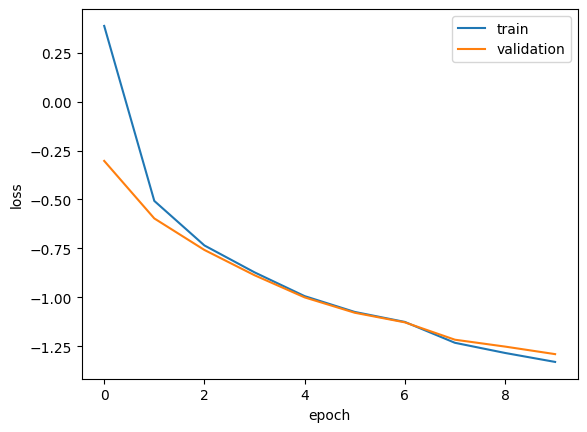

In [22]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [23]:
history_path = run_dir / "history.json"

with open(history_path, "w") as f:
    json.dump({name: [float(v) for v in values] for name, values in model.history.history.items()}, f)

print(f"Saved {len(model.history.history['loss'])} epochs to {history_path}")

Saved 10 epochs to /content/drive/My Drive/handwriting-synthesis/checkpoints/2026-11-12T15-59-48/history.json
